# Atividade Computacional I - Análise de erros na fabricação de uma peça circular

**Aluno(a):** preencher  
**Turma:** preencher  
**Data:** preencher  
**Divisão das tarefas:** preencher

Este notebook calcula as propriedades nominais de uma peça circular/cilíndrica e avalia a propagação das incertezas dimensionais no diâmetro, perímetro, área e volume.

## tl;dr

Com os valores iniciais $r = 50{,}00$ mm, $h = 10{,}00$ mm, $\Delta r = 0{,}05$ mm e $\Delta h = 0{,}02$ mm, o erro percentual do raio é de **0,100%** e o da espessura é de **0,200%**. O volume fica sensível às duas dimensões: no caso inicial, o raio contribui **0,200%** para o erro percentual do volume e a espessura também contribui **0,200%**. Para os processos comparados, a usinagem de precisão tem o menor erro, mas a escolha recomendada depende da aplicação: impressão 3D convencional para protótipo visual, usinagem convencional para tampa e espaçador, e usinagem de precisão para flange, vedação ou rotação.

## Contexto e métodos

A peça tem raio nominal $r=50{,}00$ mm e espessura $h=10{,}00$ mm. As propriedades calculadas são:

$$D = 2r$$
$$P = 2\pi r$$
$$A = \pi r^2$$
$$V = \pi r^2h$$

As incertezas são propagadas por aproximação linear:

$$\frac{\Delta D}{D} \approx \frac{\Delta r}{r}$$
$$\frac{\Delta P}{P} \approx \frac{\Delta r}{r}$$
$$\frac{\Delta A}{A} \approx 2\frac{\Delta r}{r}$$
$$\frac{\Delta V}{V} \approx 2\frac{\Delta r}{r} + \frac{\Delta h}{h}$$

### Hipóteses principais

As fórmulas de propagação usam aproximação linear, portanto são mais adequadas para pequenas incertezas em relação às dimensões nominais. A verificação direta compara essa aproximação com o cálculo exato usando dimensões máximas e mínimas.

## Setup

In [1]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from IPython.display import display

plt.style.use('seaborn-v0_8-whitegrid')
pd.set_option('display.float_format', lambda x: f'{x:,.6f}')

## Parâmetros do problema

In [2]:
r = 50.00      # raio nominal, em mm
h = 10.00      # espessura nominal, em mm
delta_r = 0.05 # incerteza do raio, em mm
delta_h = 0.02 # incerteza da espessura, em mm

params = pd.DataFrame({
    'Grandeza': ['Raio', 'Espessura'],
    'Valor nominal (mm)': [r, h],
    'Incerteza absoluta (mm)': [delta_r, delta_h],
    'Erro relativo': [delta_r / r, delta_h / h],
    'Erro percentual (%)': [100 * delta_r / r, 100 * delta_h / h],
})
display(params)

,Grandeza,Valor nominal (mm),Incerteza absoluta (mm),Erro relativo,Erro percentual (%)
0,Raio,50.000000,0.050000,0.001000,0.100000
1,Espessura,10.000000,0.020000,0.002000,0.200000


## 3. Cálculo das propriedades nominais

In [3]:
D = 2 * r
P = 2 * np.pi * r
A = np.pi * r**2
V = np.pi * r**2 * h

nominais = pd.DataFrame({
    'Grandeza': ['Diâmetro', 'Perímetro', 'Área da face circular', 'Volume'],
    'Símbolo': ['D', 'P', 'A', 'V'],
    'Valor nominal': [D, P, A, V],
    'Unidade': ['mm', 'mm', 'mm²', 'mm³'],
})
display(nominais)

,Grandeza,Símbolo,Valor nominal,Unidade
0,Diâmetro,D,100.000000,mm
1,Perímetro,P,314.159265,mm
2,Área da face circular,A,"7,853.981634",mm²
3,Volume,V,"78,539.816340",mm³


**Resultados nominais:** o diâmetro nominal é $100{,}00$ mm, o perímetro é aproximadamente $314{,}16$ mm, a área é aproximadamente $7.853{,}98$ mm² e o volume é aproximadamente $78.539{,}82$ mm³.

## 4. Erros no raio e na espessura

In [4]:
er_r = delta_r / r
er_h = delta_h / h

print(f'Erro relativo do raio: {er_r:.6f}')
print(f'Erro percentual do raio: {100*er_r:.3f}%')
print(f'Erro relativo da espessura: {er_h:.6f}')
print(f'Erro percentual da espessura: {100*er_h:.3f}%')

Erro relativo do raio: 0.001000
Erro percentual do raio: 0.100%
Erro relativo da espessura: 0.002000
Erro percentual da espessura: 0.200%


O raio tem erro percentual de **0,100%** e a espessura tem erro percentual de **0,200%**. Para uma peça decorativa, esses valores são mais do que suficientes, pois ficam abaixo de 1%. Para um espaçador, o erro do raio está no limite inferior da faixa sugerida de 0,1% a 0,2%, enquanto a espessura ainda é compatível com a faixa superior. Para encaixe mecânico, o raio está no limite superior da faixa de 0,05% a 0,1%, mas a espessura já é maior que o ideal. Para um componente de precisão, vedação ou rotação, as incertezas iniciais não são adequadas, pois deveriam ficar abaixo de 0,05%.

## 5. Propagação dos erros

In [5]:
delta_D = 2 * delta_r
delta_P = P * er_r
delta_A = A * (2 * er_r)
delta_V = V * (2 * er_r + er_h)

propagacao = pd.DataFrame({
    'Grandeza': ['Diâmetro', 'Perímetro', 'Área', 'Volume'],
    'Valor nominal': [D, P, A, V],
    'Erro absoluto estimado': [delta_D, delta_P, delta_A, delta_V],
    'Erro relativo estimado': [er_r, er_r, 2*er_r, 2*er_r + er_h],
    'Erro percentual estimado (%)': [100*er_r, 100*er_r, 100*2*er_r, 100*(2*er_r + er_h)],
    'Unidade': ['mm', 'mm', 'mm²', 'mm³'],
})
display(propagacao)

for _, row in propagacao.iterrows():
    print(f"{row['Grandeza']}: {row['Valor nominal']:.4f} ± {row['Erro absoluto estimado']:.4f} {row['Unidade']}")

,Grandeza,Valor nominal,Erro absoluto estimado,Erro relativo estimado,Erro percentual estimado (%),Unidade
0,Diâmetro,100.000000,0.100000,0.001000,0.100000,mm
1,Perímetro,314.159265,0.314159,0.001000,0.100000,mm
2,Área,"7,853.981634",15.707963,0.002000,0.200000,mm²
3,Volume,"78,539.816340",314.159265,0.004000,0.400000,mm³


Diâmetro: 100.0000 ± 0.1000 mm
Perímetro: 314.1593 ± 0.3142 mm
Área: 7853.9816 ± 15.7080 mm²
Volume: 78539.8163 ± 314.1593 mm³


## 6. Verificação direta

In [6]:
r_max, r_min = r + delta_r, r - delta_r
h_max, h_min = h + delta_h, h - delta_h

A_max = np.pi * r_max**2
A_min = np.pi * r_min**2
V_max = np.pi * r_max**2 * h_max
V_min = np.pi * r_min**2 * h_min

verificacao = pd.DataFrame({
    'Grandeza': ['Área', 'Volume'],
    'Valor nominal': [A, V],
    'Mínimo direto': [A_min, V_min],
    'Máximo direto': [A_max, V_max],
    'Variação direta para cima': [A_max - A, V_max - V],
    'Variação direta para baixo': [A - A_min, V - V_min],
    'Erro estimado pela propagação': [delta_A, delta_V],
    'Unidade': ['mm²', 'mm³'],
})
display(verificacao)

,Grandeza,Valor nominal,Mínimo direto,Máximo direto,Variação direta para cima,Variação direta para baixo,Erro estimado pela propagação,Unidade
0,Área,"7,853.981634","7,838.281525","7,869.697451",15.715817,15.700109,15.707963,mm²
1,Volume,"78,539.816340","78,226.049616","78,854.368461",314.552122,313.766723,314.159265,mm³


Os valores diretos e os valores estimados pela propagação são próximos, mas não exatamente iguais. A diferença ocorre porque a propagação linear ignora termos de ordem superior, como $(\Delta r)^2$ na área e produtos entre pequenas variações no volume. Como as incertezas são pequenas, esses termos adicionais são pequenos, mas não são nulos.

## 7. Gráfico do erro da área

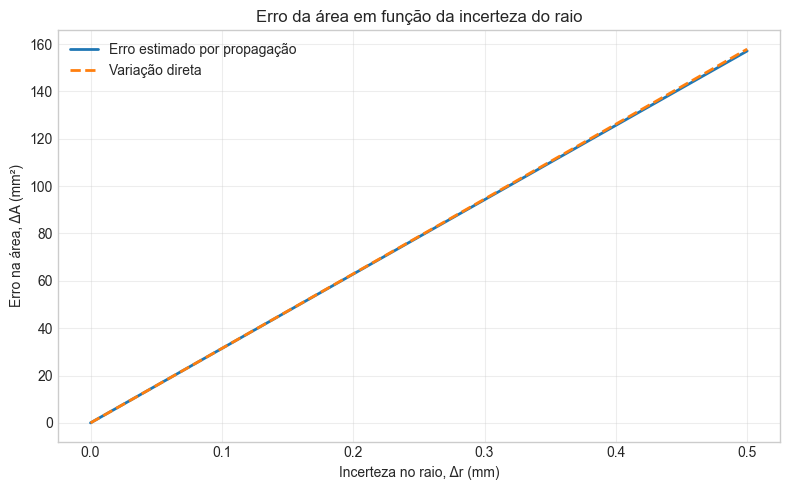

Maior Δr testado com diferença relativa até 1% entre as curvas: 0.500 mm


In [7]:
delta_r_values = np.linspace(0, 0.50, 101)
delta_A_estimado = A * (2 * delta_r_values / r)
delta_A_direto = np.pi * (r + delta_r_values)**2 - A

diff_area = np.abs(delta_A_direto - delta_A_estimado)
relative_diff_area = np.divide(diff_area, delta_A_direto, out=np.zeros_like(diff_area), where=delta_A_direto != 0)
adequado_mask = relative_diff_area <= 0.01
max_delta_r_1pct = delta_r_values[adequado_mask].max()

plt.figure(figsize=(8, 5))
plt.plot(delta_r_values, delta_A_estimado, label='Erro estimado por propagação', linewidth=2)
plt.plot(delta_r_values, delta_A_direto, label='Variação direta', linewidth=2, linestyle='--')
plt.title('Erro da área em função da incerteza do raio')
plt.xlabel('Incerteza no raio, Δr (mm)')
plt.ylabel('Erro na área, ΔA (mm²)')
plt.legend()
plt.grid(True, alpha=0.35)
plt.tight_layout()
plt.show()

print(f'Maior Δr testado com diferença relativa até 1% entre as curvas: {max_delta_r_1pct:.3f} mm')

As duas curvas são muito próximas para erros pequenos. A diferença aumenta quando $\Delta r$ aumenta, porque a expressão direta contém o termo quadrático $(\Delta r)^2$, que a aproximação linear não considera. Neste intervalo de estudo, a aproximação linear é adequada para toda a faixa de $0$ a $0{,}50$ mm se aceitarmos diferença relativa de até cerca de 1% entre as curvas; para critérios mais rigorosos, ela é especialmente boa nas menores variações de raio.

## 8. Gráfico do erro percentual do volume

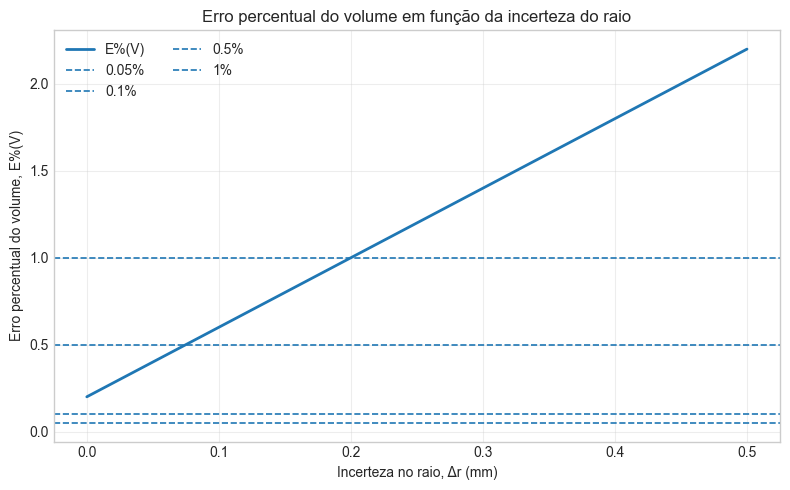

,Limite de E%(V),Δr máximo compatível (mm),Observação
0,0.05%,NaN,"impossível mantendo Δh=0,02 mm"
1,0.1%,NaN,"impossível mantendo Δh=0,02 mm"
2,0.5%,0.075000,"possível com Δh=0,02 mm"
3,1%,0.200000,"possível com Δh=0,02 mm"


In [8]:
volume_error_percent = 100 * (2 * delta_r_values / r + delta_h / h)
limits = [0.05, 0.1, 0.5, 1.0]

plt.figure(figsize=(8, 5))
plt.plot(delta_r_values, volume_error_percent, label='E%(V)', color='tab:blue', linewidth=2)
for limit in limits:
    plt.axhline(limit, linestyle='--', linewidth=1.2, label=f'{limit:g}%')
plt.title('Erro percentual do volume em função da incerteza do raio')
plt.xlabel('Incerteza no raio, Δr (mm)')
plt.ylabel('Erro percentual do volume, E%(V)')
plt.legend(ncol=2)
plt.grid(True, alpha=0.35)
plt.tight_layout()
plt.show()

threshold_rows = []
for limit in limits:
    max_allowed = (limit / 100 - delta_h / h) * r / 2
    threshold_rows.append({
        'Limite de E%(V)': f'{limit:g}%',
        'Δr máximo compatível (mm)': max_allowed if max_allowed >= 0 else np.nan,
        'Observação': 'possível com Δh=0,02 mm' if max_allowed >= 0 else 'impossível mantendo Δh=0,02 mm'
    })
display(pd.DataFrame(threshold_rows))

Mantendo $\Delta h=0{,}02$ mm, o volume já possui contribuição de **0,200%** apenas pela espessura. Por isso, limites de 0,05% e 0,1% são impossíveis com essa espessura. Aplicações de baixa precisão, como protótipos visuais, aceitam uma faixa maior de $\Delta r$; aplicações médias exigem valores menores; aplicações de alta precisão exigiriam reduzir também $\Delta h$.

## 9. Comparação das contribuições

,Dimensão,Contribuição ao erro relativo do volume,Contribuição percentual (%)
0,Raio,0.002000,0.200000
1,Espessura,0.002000,0.200000


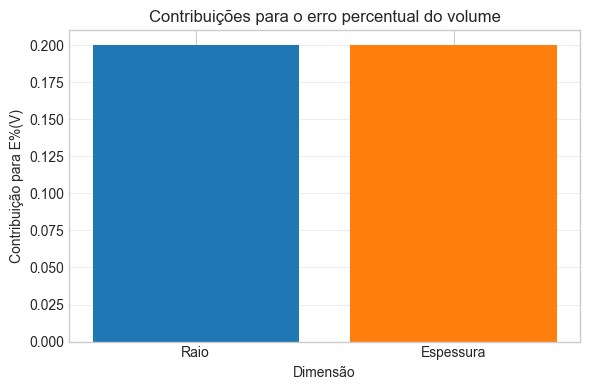

In [9]:
contrib_raio = 2 * delta_r / r
contrib_espessura = delta_h / h

contribuicoes = pd.DataFrame({
    'Dimensão': ['Raio', 'Espessura'],
    'Contribuição ao erro relativo do volume': [contrib_raio, contrib_espessura],
    'Contribuição percentual (%)': [100 * contrib_raio, 100 * contrib_espessura]
})
display(contribuicoes)

plt.figure(figsize=(6, 4))
plt.bar(contribuicoes['Dimensão'], contribuicoes['Contribuição percentual (%)'], color=['tab:blue', 'tab:orange'])
plt.title('Contribuições para o erro percentual do volume')
plt.xlabel('Dimensão')
plt.ylabel('Contribuição para E%(V)')
plt.grid(axis='y', alpha=0.35)
plt.tight_layout()
plt.show()

Neste caso inicial, raio e espessura contribuem igualmente para o erro percentual do volume: **0,200%** cada. A empresa deveria priorizar a dimensão cuja redução de incerteza for mais barata ou mais crítica para a aplicação; se o foco for área, diâmetro, encaixe ou rotação, o raio tende a ser prioridade. O erro do raio aparece multiplicado por dois porque o volume depende de $r^2$; ao derivar ou linearizar $r^2$, a variação relativa fica aproximadamente $2\Delta r/r$.

## 10. Análise dos processos de fabricação

,Processo,Δr (mm),Δh (mm),Erro % no diâmetro,Erro % na área,Erro % no volume,Volume mínimo (mm³),Volume máximo (mm³)
0,Impressão 3D convencional,0.300000,0.200000,0.600000,1.200000,3.200000,"76,048.162658","81,074.824001"
1,Usinagem convencional,0.050000,0.050000,0.100000,0.200000,0.700000,"77,990.901171","79,090.459385"
2,Usinagem de precisão,0.010000,0.010000,0.020000,0.040000,0.140000,"78,429.895151","78,649.806643"


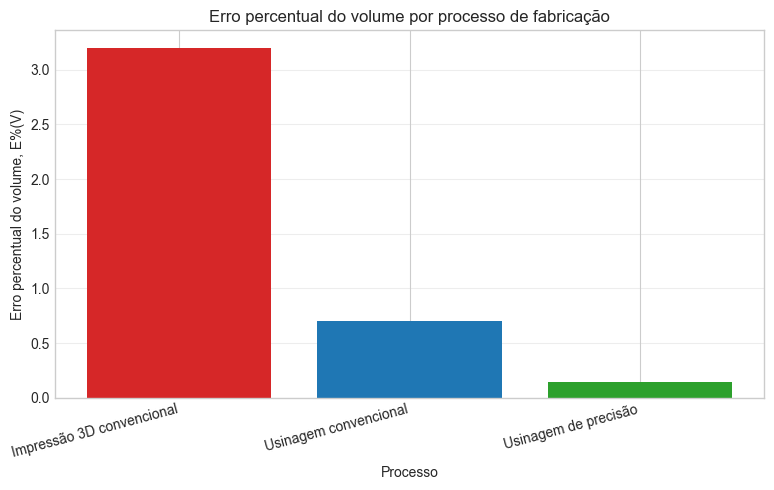

In [10]:
processos = pd.DataFrame({
    'Processo': ['Impressão 3D convencional', 'Usinagem convencional', 'Usinagem de precisão'],
    'Δr (mm)': [0.30, 0.05, 0.01],
    'Δh (mm)': [0.20, 0.05, 0.01],
})

linhas = []
for _, proc in processos.iterrows():
    dr = proc['Δr (mm)']
    dh = proc['Δh (mm)']
    erro_D_pct = 100 * dr / r
    erro_A_pct = 100 * 2 * dr / r
    erro_V_pct = 100 * (2 * dr / r + dh / h)
    v_min_proc = np.pi * (r - dr)**2 * (h - dh)
    v_max_proc = np.pi * (r + dr)**2 * (h + dh)
    linhas.append({
        'Processo': proc['Processo'],
        'Δr (mm)': dr,
        'Δh (mm)': dh,
        'Erro % no diâmetro': erro_D_pct,
        'Erro % na área': erro_A_pct,
        'Erro % no volume': erro_V_pct,
        'Volume mínimo (mm³)': v_min_proc,
        'Volume máximo (mm³)': v_max_proc,
    })

processos_resultado = pd.DataFrame(linhas)
display(processos_resultado)

plt.figure(figsize=(8, 5))
plt.bar(processos_resultado['Processo'], processos_resultado['Erro % no volume'], color=['tab:red', 'tab:blue', 'tab:green'])
plt.title('Erro percentual do volume por processo de fabricação')
plt.xlabel('Processo')
plt.ylabel('Erro percentual do volume, E%(V)')
plt.xticks(rotation=15, ha='right')
plt.grid(axis='y', alpha=0.35)
plt.tight_layout()
plt.show()

A impressão 3D convencional apresenta o maior erro percentual no volume, por causa das maiores incertezas no raio e na espessura. A usinagem convencional reduz bastante o erro e pode atender aplicações intermediárias. A usinagem de precisão entrega a menor variação e é a opção mais indicada para aplicações críticas, embora normalmente custe mais.

## 11. Recomendação para a empresa

In [11]:
recomendacoes = pd.DataFrame({
    'Situação': [
        'Protótipo visual',
        'Tampa sem encaixe crítico',
        'Espaçador mecânico',
        'Flange com necessidade de alinhamento',
        'Componente de vedação ou rotação',
    ],
    'Processo recomendado': [
        'Impressão 3D convencional',
        'Usinagem convencional',
        'Usinagem convencional',
        'Usinagem de precisão',
        'Usinagem de precisão',
    ],
    'Justificativa': [
        'A tolerância é suficiente para visualização e o custo tende a ser menor.',
        'Oferece erro baixo sem exigir o processo mais caro.',
        'Atende melhor à faixa de precisão intermediária necessária para montagem.',
        'A necessidade de alinhamento exige menor erro dimensional.',
        'Vedação e rotação exigem controle rigoroso para evitar folgas, vazamentos ou vibrações.',
    ]
})
display(recomendacoes)

,Situação,Processo recomendado,Justificativa
0,Protótipo visual,Impressão 3D convencional,A tolerância é suficiente para visualização e ...
1,Tampa sem encaixe crítico,Usinagem convencional,Oferece erro baixo sem exigir o processo mais ...
2,Espaçador mecânico,Usinagem convencional,Atende melhor à faixa de precisão intermediári...
3,Flange com necessidade de alinhamento,Usinagem de precisão,A necessidade de alinhamento exige menor erro ...
4,Componente de vedação ou rotação,Usinagem de precisão,Vedação e rotação exigem controle rigoroso par...


A empresa não deve escolher sempre o processo mais preciso, pois maior precisão normalmente aumenta o custo. A decisão correta é escolher o processo que entrega precisão suficiente para a função da peça. Para vedação ou rotação, a usinagem de precisão é a melhor entre as três opções, mas se a especificação real exigir erro inferior a 0,05% em todas as dimensões, seria necessário reduzir ainda mais a incerteza da espessura ou adotar inspeção/controle adicional.

## 12. Checklist da entrega

- Identificação dos alunos e divisão das tarefas: preencher no topo do notebook.
- Equações utilizadas e códigos comentados: incluídos nas seções de métodos e células de código.
- Resultados com unidades: incluídos nas tabelas.
- Tabela comparativa dos processos: incluída na Seção 10.
- Gráfico do erro da área: incluído na Seção 7.
- Gráfico do erro percentual do volume: incluído na Seção 8.
- Gráfico de barras das contribuições do raio e da espessura: incluído na Seção 9.
- Gráfico de comparação dos processos: incluído na Seção 10.
- Respostas às perguntas e recomendação final: incluídas nas seções correspondentes.

## 13. Conclusão

O erro do raio afeta diretamente o diâmetro e o perímetro, mas seu efeito fica mais importante na área e no volume, porque essas grandezas dependem de $r^2$. No volume, o raio aparece com contribuição relativa $2\Delta r/r$, enquanto a espessura aparece como $\Delta h/h$; no caso inicial, as duas contribuições foram iguais, mas o raio continua sendo uma dimensão crítica por influenciar também diâmetro, perímetro e área. Aplicações diferentes exigem níveis diferentes de precisão porque peças decorativas toleram pequenas variações visuais, enquanto encaixes, flanges, vedações e componentes rotativos podem sofrer folgas, interferências, vazamentos e vibrações. Assim, recomenda-se impressão 3D convencional para protótipos visuais, usinagem convencional para usos sem exigência crítica ou de precisão intermediária, e usinagem de precisão para flange, vedação ou rotação, com a ressalva de que requisitos reais abaixo de 0,05% podem exigir controle adicional. Os gráficos auxiliam a decisão de engenharia ao mostrar como o erro cresce com $\Delta r$, quando a aproximação linear é aceitável e quais processos atendem melhor aos limites de precisão necessários.